# CIFAR-10 using MLP and CNN

### Team 8:

Almir Alves

Erbert Gadelha

Felipe Barreto

João Pedro

Vinicius Barbosa

### Libs

In [26]:
import torch
import torchvision
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms

from google.colab import drive

import matplotlib.pyplot as plt
import numpy as np
from sklearn import metrics
import pandas as pd

import seaborn as sns

from tqdm import tqdm

from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

### Setting up to work with either CPU or GPU

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


### Dataset Setup

In [ ]:
drive.mount('/content/drive')

transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

train_dataset = torchvision.datasets.CIFAR10(root='/content/drive/MyDrive/data', train=True, download=True, transform=transform)

test_dataset = torchvision.datasets.CIFAR10(
    root='/content/drive/MyDrive/data',
    train=False,
    download=True,
    transform=transform
)

100%|██████████| 170M/170M [18:37<00:00, 153kB/s]


### Defining metrics helper

In [28]:
def get_scores(targets, predictions):
    return {
        "accuracy": metrics.accuracy_score(targets, predictions),
        "balanced_accuracy": metrics.balanced_accuracy_score(targets, predictions),
        "precision": metrics.precision_score(targets, predictions, average="weighted"),
        "recall": metrics.recall_score(targets, predictions, average="weighted"),
        "f1_score": metrics.f1_score(targets, predictions, average="weighted")
    }

## Approach using MLP (19/05/2025 - 02/06/2025)

### 1 - Initial hyperparameters for the base project

##### input_size:

- Value: 32 * 32 * 3 = 3072

- Objective: to measure the dimensions of CIFAR-10 images: 32x32 pixels, 3 RGB channels

##### num_classes:

- Value: 10

- Objective: to define the number of classes in CIFAR-10. It is implemented directly in:

`self.fc_output = nn.Linear(84, 10)`

##### learning_rate:

- Value: 0.0001

- Objective: to define the training rate

##### num_epochs:

- Value: 100

- Objective: to measure how many times all samples will undergo training

##### batch_size:

- Value: 16

- Objective: to define the number of samples per training flow

#### Structuring of the layers:

- self.fc_input: Receives the input data with input_size features and transforms them into 64 neurons. This is the first fully connected layer, which learns patterns from the input data.

`self.fc_input = nn.Linear(input_size, 64)`

- self.fc_hidden1: Takes the 64 neurons from the previous layer and transforms them into 128 neurons. This hidden layer learns more complex patterns and representations.

`self.fc_hidden1 = nn.Linear(64, 128)`

- self.fc_hidden2: Takes the 128 neurons from the previous layer and transforms them into 64 neurons. This is the second hidden layer, which further processes the learned representations.

`self.fc_hidden2 = nn.Linear(128, 64)`


- self.fc_output: Output layer, from 64 to num_classes (10 for CIFAR-10).

`self.fc_output = nn.Linear(84, 10)`

#### Activation and Loss Functions

- activation_function: nn.ELU()

Initially, the nn.ReLU() function was used, which is calculated by `f(x) = x for x > 0, 0 otherwise`. However to eliminate the issue caused by "dead neurons" (neurons that become inactive due to negative inputs), we apply the nn.ELU() function, which works with an exponential shape that provides a smoother activation centered around zero (which improves convergence). It is calculated as follows:

`f(x) = a(e^x - 1)`

- loss_function: nn.CrossEntropyLoss()

`Calculation: negative of the logarithm of the predicted probability for the correct class`

Note: All the following metric values ​​were measured based on data from the test set.

#### New structure of layers

Following the training conducted on the model using an MLP, an additional hidden layer was implemented.

`self.fc_input = nn.Linear(64 * 8 * 8, 128)`

`self.fc_hidden1 = nn.Linear(128, 256)`

`self.fc_hidden2 = nn.Linear(256, 128)`

`self.fc_hidden3 = nn.Linear(128, 64)`

`self.fc_output = nn.Linear(64, 10)`

#### Dropout

Subsequently, dropout was also implemented after each layer. Also, the dropout rate increases in layers closer to the output layer, with the goal of improving the model's accuracy.

`self.fc_input = nn.Linear(64 * 8 * 8, 128)`

`self.dropout1 = nn.Dropout(p=0.2)`

`self.fc_hidden1 = nn.Linear(128, 256)`

`self.dropout2 = nn.Dropout(p=0.4)`

`self.fc_hidden2 = nn.Linear(256, 128)`

`self.dropout3 = nn.Dropout(p=0.6)`

`self.fc_hidden3 = nn.Linear(128, 64)`

`self.fc_output = nn.Linear(64, 10)`

### 3 - Final test and execution

To finalize the model training, the final results obtained, with an average error rate of 0.3467, were:

`Scores of your model`

`{'accuracy': 0.5314, 'balanced_accuracy': 0.5314, 'precision': 0.535149982317983, 'recall': 0.5314, 'f1_score': 0.5312550135782537}`

### Defining the MLP model

In [ ]:
# 3072 (input) → 128 → 256 → 128 → 64 → 10 (output)

class MLP(nn.Module):
  def __init__(self, input_size, num_classes, activation_function):
    super(MLP, self).__init__()
    # Defining activation functions and fully-connected layers
    self.activation_function = activation_function
    self.fc_input = nn.Linear(input_size, 128)
    self.dropout1 = nn.Dropout(0.2) # It was added 20% dropout to hidden layer 1
    self.fc_hidden1 = nn.Linear(128, 256)
    self.dropout2 = nn.Dropout(0.4) # It was added 40% dropout to hidden layer 2
    self.fc_hidden2 = nn.Linear(256, 128)
    self.dropout3 = nn.Dropout(0.6) # It was added 60% dropout to hidden layer 3 (I read that layers near the output might benefit from a higher dropout rate, so I decided to give it a try.)
    self.fc_hidden3 = nn.Linear(128, 64)
    self.fc_output = nn.Linear(64, num_classes)

  def forward(self, x):
    x = self.activation_function(self.fc_input(x))

    x = self.activation_function(self.fc_hidden1(x))
    x = self.dropout1(x)

    x = self.activation_function(self.fc_hidden2(x))
    x = self.dropout2(x)

    x = self.activation_function(self.fc_hidden3(x))
    x = self.dropout3(x)

    x = self.fc_output(x)
    return x

### Hyperparameters

In [ ]:
input_size = 32*32*3 # 32x32 RGB images
num_classes = 10

learning_rate = 0.0001 # Lower the learning rate even further
num_epochs = 100 # I’ve set it back to 100 epochs to see how it performs now that I’ve added dropouts.
batch_size = 16
activation_function = nn.ELU() # Attempting to optimize issues caused by ReLU

loss_function = nn.CrossEntropyLoss()

### Loaders

In [ ]:
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

### Training Loop

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Build the model
mlp = MLP(input_size=input_size, num_classes=num_classes, activation_function=activation_function)
mlp.to(device)

# Setting optimizer up
optimizer = torch.optim.Adam(mlp.parameters(), lr=learning_rate, weight_decay=0.0001) #Here I added a penalty for large weights.

# Early stopping setup
best_loss = float('inf')
patience = 5
patience_counter = 0

#Ensure that the active MLP model is the one used for training.
mlp.train()

# Start training epochs loop
for epoch in tqdm(range(num_epochs)):
  epoch_loss = 0.0
  for i, (images, labels) in enumerate(train_loader):
    images = images.view(-1,32*32*3).to(device) # flattenning images
    labels = labels.to(device)

    # Forward pass
    optimizer.zero_grad()
    outputs = mlp(images)

    # Backward pass
    loss = loss_function(outputs, labels)
    loss.backward()
    optimizer.step()

    epoch_loss += loss.item()

    if (i+1) % 1000 == 0:
      tqdm.write(f' Epoch {epoch + 1}/{num_epochs}, Step {i+1}/{len(train_dataset) // batch_size}, Loss: {loss}')

  epoch_loss /= len(train_loader)
  tqdm.write(f'Epoch {epoch+1} average loss: {epoch_loss:.4f}')

  # Early stopping using loss value
  if epoch_loss < best_loss:
    best_loss = epoch_loss
    patience_counter = 0
  else:
    patience_counter += 1
    if patience_counter >= patience:
      tqdm.write("Early stopping triggered.")
      break

  0%|          | 0/100 [00:06<?, ?it/s]

 Epoch 1/100, Step 1000/3125, Loss: 2.139523506164551


  0%|          | 0/100 [00:13<?, ?it/s]

 Epoch 1/100, Step 2000/3125, Loss: 1.6692163944244385


  0%|          | 0/100 [00:19<?, ?it/s]

 Epoch 1/100, Step 3000/3125, Loss: 1.7302439212799072


... (790 outputs left out)

 99%|█████████▉| 99/100 [34:43<00:21, 21.20s/it]

 Epoch 100/100, Step 3000/3125, Loss: 0.7323436737060547


100%|██████████| 100/100 [34:44<00:00, 20.84s/it]

Epoch 100 average loss: 0.5325


### Evaluate model (accuracy, precision, recall)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

mlp.eval()
y_pred = []
y_true = []
with torch.no_grad():
    for images, labels in test_loader:
        #images, labels = images.to(device), labels.to(device)
        images = images.view(-1,32*32*3).to(device)
        labels = labels.to(device)
        outputs = mlp(images)
        _, predicted = torch.max(outputs, 1)

        y_pred.extend(predicted.cpu().numpy())
        y_true.extend(labels.cpu().numpy())

scores = get_scores(y_true, y_pred)
acc = scores["accuracy"]

for element in scores:
  print(f"{element}: {scores[element] * 100:.2f}%")

accuracy: 53.14%
balanced_accuracy: 53.14%
precision: 53.51%
recall: 53.14%
f1_score: 53.13%


### Confusion Matrix

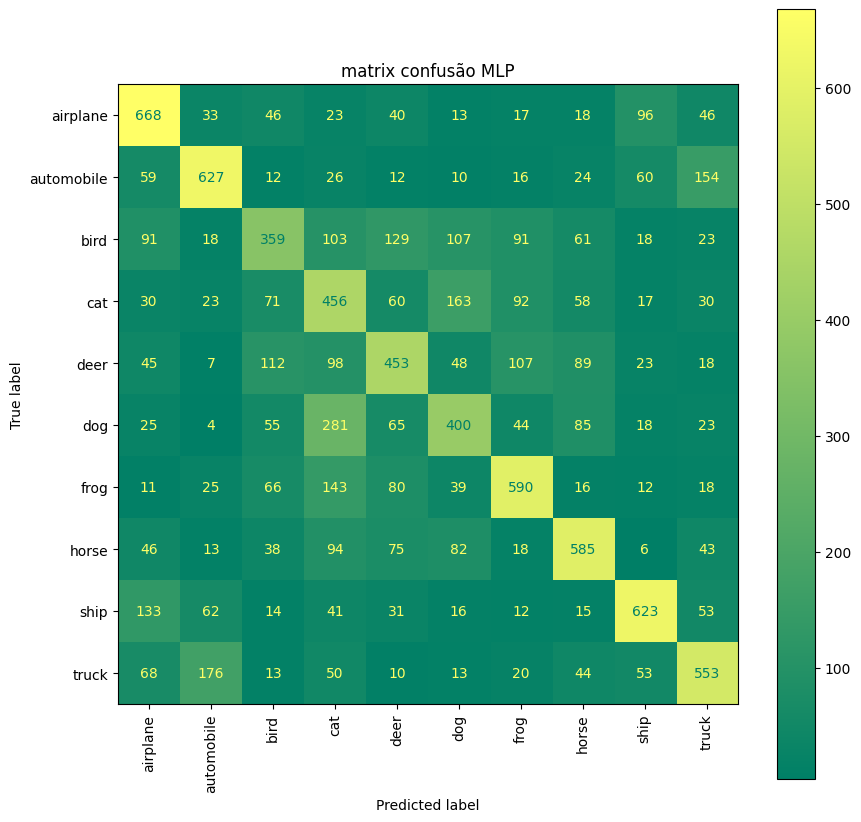

In [ ]:
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=train_dataset.classes)

fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(xticks_rotation='vertical', ax=ax, cmap='summer')
plt.title('matrix confusão MLP')
plt.show()

### Correct matches per image in graph format

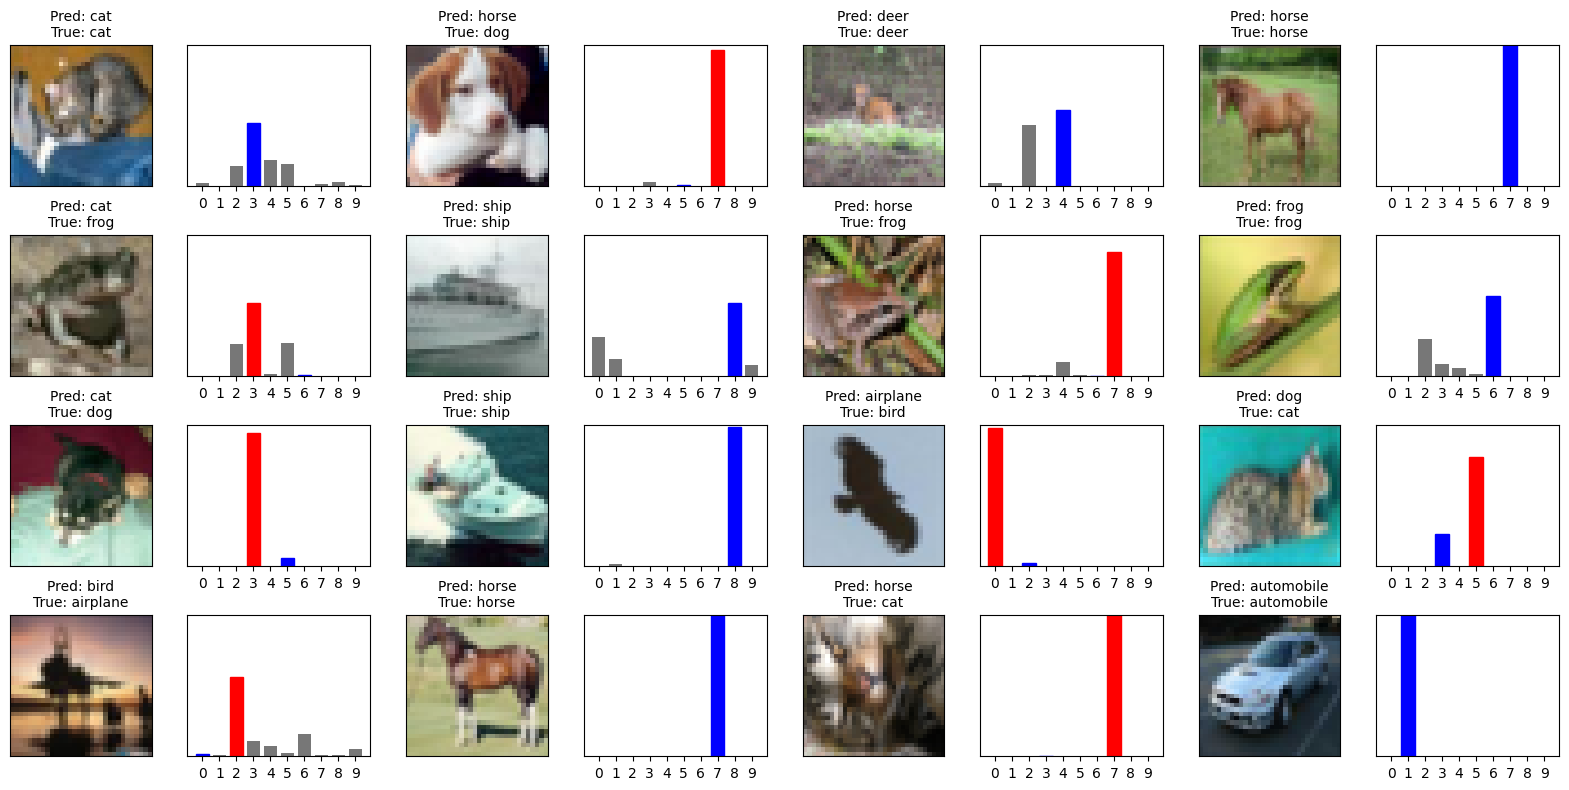

In [ ]:
def plot_value_array(predictions_array, true_label):
    if isinstance(predictions_array, torch.Tensor):
        predictions_array = (predictions_array.detach().cpu().numpy())
    true_label = int(true_label)
    predicted_label = np.argmax(predictions_array)

    plt.grid(False)
    plt.xticks(range(len(predictions_array)))
    plt.yticks([])
    bars = plt.bar(range(len(predictions_array)), predictions_array, color="#777777")
    plt.ylim([0, 1])

    bars[predicted_label].set_color('red')
    bars[true_label].set_color('blue')

mlp.eval()
num_rows = 4
num_cols = 4
num_images = num_rows * num_cols

fig = plt.figure(figsize=(2 * 2 * num_cols, 2 * num_rows))

y_pred = []
y_true = []

with torch.no_grad():
    for i, (image, label) in enumerate(test_loader):
        if i >= num_images:
            break

        image_vis = image[0].cpu() * 0.5 + 0.5
        image_vis = image_vis.permute(1, 2, 0)

        # Classify with the model
        image_input = image.view(image.size(0), -1).to(device)  # flattens for the MLP
        output = mlp(image_input)
        probabilities = F.softmax(output, dim=1)[0]
        _, predicted = torch.max(output, 1)

        y_pred.extend(predicted.cpu().numpy())
        y_true.extend(label.cpu().numpy())

        # Plot of the classified image
        plt.subplot(num_rows, 2 * num_cols, 2 * i + 1)
        plt.grid(False)
        plt.xticks([])
        plt.yticks([])
        true_label = label[0].item()
        pred_label = predicted[0].item()
        title = f'Pred: {test_dataset.classes[pred_label]}\nTrue: {test_dataset.classes[true_label]}'
        plt.title(title, fontsize=10)
        plt.imshow(image_vis)

        # Probability plot
        plt.subplot(num_rows, 2 * num_cols, 2 * i + 2)
        plot_value_array(probabilities, true_label)

plt.tight_layout()
plt.show()

In [ ]:
torch.save(mlp.state_dict(), 'mlp_CIFAR_10.pth')

## Approach using CNN (04/06/2025 - 16/06/2025)

### 1 - Initial hyperparameters for the base project

##### input_size:

- Initial value: 32 * 32 * 3 = 3072

- Objective: to measure the dimensions of CIFAR-10 images: 32x32 pixels, 3 RGB channels

##### num_classes:

- Value: 10

- Objective: to define the number of classes in CIFAR-10. It is implemented directly in:

`self.fc_output = nn.Linear(84, 10)`

##### learning_rate:

- Value: 0.001

- Objective: to define the training rate

##### num_epochs:

- Value: 10

- Objective: to measure how many times all samples will undergo training

##### batch_size:

- Value: 32

- Objective: to define the number of samples per training flow

#### Structuring of the layers:

- self.conv1: Receives images with 3 RGB channels. 32 filters of size 3 x 3 are applied, with each one learning a different pattern. After applying self.pool, the output consists of 32 x 16 x 16 neurons.

`self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)`

- self.conv2: takes 32 filters as input and applies 64 filters of size 3 x 3 to them. After applying self.pool, the output will consist of 64 x 8 x 8 neurons.

`self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)`

- self.pool: Retains the maximum value within 2 x 2 blocks (max pooling) and halves the height and width of the image (stride = 2) for each convolutional layer.

`self.pool = nn.MaxPool2d(kernel_size=2, stride=2)`

- self.fc_hidden1: First hidden layer, from 4096 (64 x 8 x 8) to 120 neurons.

`self.fc_hidden1 = nn.Linear(64 * 8 * 8, 120)`

- self.fc_hidden2: Second hidden layer, from 120 to 84 neurons.

`self.fc_hidden2 = nn.Linear(120, 84)`

- self.fc_output: Output layer, from 84 to num_classes (10 for CIFAR-10).

`self.fc_output = nn.Linear(84, 10)`

#### Activation and Loss Functions

- activation_function: nn.ReLU()

`Calculation: f(x) = x for x > 0, 0 otherwise`

- loss_function: nn.CrossEntropyLoss()

`Calculation: negative of the logarithm of the predicted probability for the correct class`

Note: All the following metric values ​​were measured based on data from the test set.

#### Initial Test

Based solely on the test using default values, an average final loss of 0.1874 was achieved after 2 minutes and 40 seconds of execution, yielding metric values ​​significantly superior to those of the MLP:

`Scores of your model`

`{'accuracy': 0.6991, 'balanced_accuracy': np.float64(0.6990999999999999), 'precision': 0.7065330319437901, 'recall': 0.6991, 'f1_score': 0.6998097397518164}`

### 2 - Changing the activation function

#### 1. LeakyReLU( )

To eliminate the issue caused by "dead neurons" (neurons that become inactive due to negative inputs), we apply the leakyReLU() activation function. In this function, values ​​below 0 are multiplied by a constant, which reduces their impact on data propagation without completely nullifying their contribution, as the gradient calculation is still preserved. It is worth noting that activation functions introduce non-linearity into the model, enabling it to learn complex patterns. With an average error rate of 0.1335, the following metrics were obtained:

`Scores of your model`

`{'accuracy': 0.7276, 'balanced_accuracy': 0.7276, 'precision': 0.7280877130389911, 'recall': 0.7276, 'f1_score': 0.7265243441585986}`

#### 2. ELU( )

Applying the nn.ELU() function works similarly to LeakyReLU, but with an exponential shape that provides a smoother activation centered around zero (which improves convergence). It is calculated as follows:

`f(x) = a(e^x - 1)`

With a final average loss rate of 0.1476, we obtain the following metrics using ELU:

`Scores of your model`

`{'accuracy': 0.707, 'balanced_accuracy': 0.7070000000000001, 'precision': 0.7103413580966371, 'recall': 0.707, 'f1_score': 0.707637929058539}`

Following the training conducted on the model using an MLP, an additional hidden layer was implemented.

`self.fc_input = nn.Linear(64 * 8 * 8, 128)`

`self.fc_hidden1 = nn.Linear(128, 256)`

`self.fc_hidden2 = nn.Linear(256, 128)`

`self.fc_hidden3 = nn.Linear(128, 64)`

`self.fc_output = nn.Linear(64, 10)`

Training with LeakyReLU, with a final average loss of 0.1650, the following metrics were obtained:

`Scores of your model`

`{'accuracy': 0.7231, 'balanced_accuracy': 0.7231, 'precision': 0.7288166274245367, 'recall': 0.7231, 'f1_score': 0.7237624521057013}`

Meanwhile, with ELU, with a final average loss rate of 0.1829, the following was obtained:

`Scores of your model`

`{'accuracy': 0.7095, 'balanced_accuracy': 0.7095, 'precision': 0.7158495099885597, 'recall': 0.7095, 'f1_score': 0.7117117183329135}`

For this reason, it was decided to maintain the original structure of the internal layers and use LeakyReLU, as it yielded the best metrics.

#### Dropout

Subsequently, dropout was implemented after each internal layer. Following a series of tests, the chosen set of dropout values ​​helped increase accuracy without significantly penalizing the final average loss (0.3606).

`self.fc_hidden1 = nn.Linear(64 * 8 * 8, 120)`

`self.dropout1 = nn.Dropout(p=0.25)`

`self.fc_hidden2 = nn.Linear(120, 84)`

`self.dropout2 = nn.Dropout(p=0.15)`

`self.fc_output = nn.Linear(84, 10)`

The metrics obtained were as follows:

`Scores of your model`

`{'accuracy': 0.7442, 'balanced_accuracy': np.float64(0.7442000000000001), 'precision': 0.7414908068207763, 'recall': 0.7442, 'f1_score': 0.7418330680354339}`

#### Num_epochs

Increasing the number of epochs allows the training process to last longer. However, to prevent overfitting, additional implementations are required, such as:

- Data augmentation: artificial increase in the diversity of training data.

- Scheduler: automatically adjusts the learning rate throughout the epochs.

Thus, even with an average learning loss rate of 0.6822 (as training becomes more difficult), it is possible to obtain the following metrics:

`Scores of your model`

`{'accuracy': 0.8022, 'balanced_accuracy': np.float64(0.8022), 'precision': 0.8035697748931844, 'recall': 0.8022, 'f1_score': 0.8008207532440909}`

#### Reduction in the average error rate

In an effort to reduce the model's average error rate, the following were implemented:

- Batch Normalization: normalizes each batch by calculating the mean of the internal data, making training faster and more stable.

- Global Average Pooling: reduces the number of parameters in dense layers by calculating the mean of the activation data.

As a result, the average error rate became 0.5415, even though the metrics remained the same.

`Scores of your model`

`{'accuracy': 0.8063, 'balanced_accuracy': np.float64(0.8063), 'precision': 0.8074096032837748, 'recall': 0.8063, 'f1_score': 0.805642736297445}`

### 3 - Final test and execution

To finalize the model training, two additional layers were added to the CNN, resulting in a total of 5 CNN layers, 2 hidden layers, and 1 output layer, and a grid search was executed.

| Hyperparameter | Value 1 | Value 2 |
|---------|----------|----------|
| optimizer | torch.optim.Adam | torch.optim.SGD |
| learning_rate | 0.001 | 0.01 |

Consequently, the final results obtained were:

| Model | Accuracy | Balanced Accuracy | Precision | Recall | F1 Score |
|---------|----------|----------|----------|----------|----------|
| optimizer = 'torch.optim.adam.Adam', learning rate = 0.001 | 0.8252 | 0.8252 | 0.830036584317951 | 0.8252 | 0.8233874900102619
| optimizer = 'torch.optim.adam.Adam', learning rate = 0.01 | 0.8034 | 0.8033999999999999 | 0.8243924832382706 | 0.8034 | 0.8032698942261175 |
| optimizer = 'torch.optim.sgd.SGD', learning rate = 0.001 | 0.7597 | 0.7596999999999999 | 0.762693555187357 | 0.7597 | 0.7562581435432814 |
| optimizer = 'torch.optim.sgd.SGD', learning rate = 0.01 | 0.8138 | 0.8138 | 0.8154975369598535 | 0.8138 | 0.8111221280300052 |

Resulting at the model using the Adam optimizer and a learning rate of 0.001 as the best model, with an accuracy of 0.8252.

#### 3.1 Loading the Dataset

##### Dataset Setup

In [4]:
drive.mount('/content/drive')
transform_train = transforms.Compose([
    transforms.RandomHorizontalFlip(),                                          # random horizontal flip
    transforms.RandomResizedCrop(32, scale=(.7, 1)),                            # random resize
    transforms.ColorJitter(brightness=(.7,1), contrast=(1,1.5), saturation=0),  # changes in color
    transforms.ToTensor(),                                                      # normalize to [0,1]
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))                      # normalize to [-1,1]
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

train_dataset = torchvision.datasets.CIFAR10(root='/content/drive/MyDrive/data_cnn', train=True, download=True, transform=transform_train)

test_dataset = torchvision.datasets.CIFAR10(root='/content/drive/MyDrive/data_cnn', train=False, download=True, transform=transform_test)

Mounted at /content/drive


100%|██████████| 170M/170M [1:02:40<00:00, 45.3kB/s]


##### Title Visualization

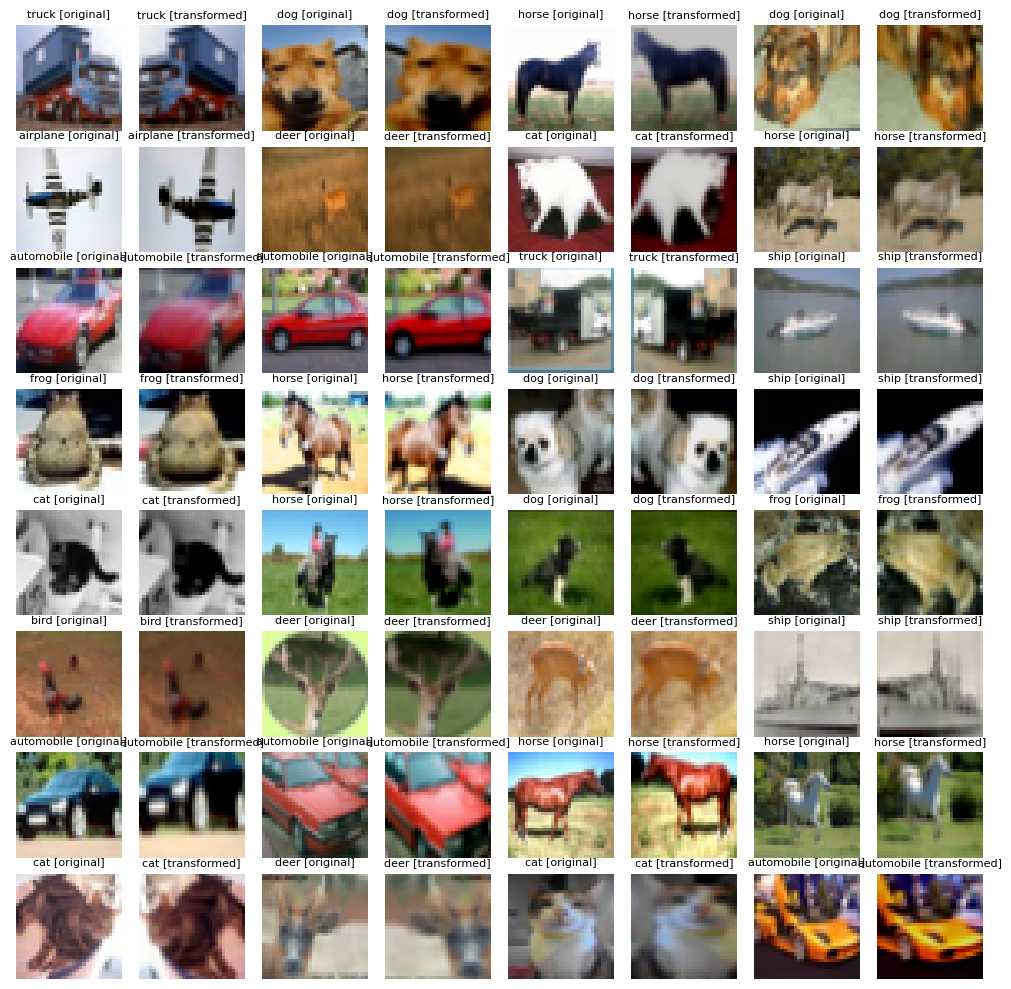

In [5]:
W_grid = 8
L_grid = 8

fig, axes = plt.subplots(L_grid, W_grid, figsize=(10, 10))
axes = axes.ravel()

n_train = len(train_dataset)

for i in range(int((W_grid * L_grid)/2)):
    index = np.random.randint(0, n_train)

    axes[i*2].imshow(train_dataset.data[index])
    axes[i*2].set_title(train_dataset.classes[train_dataset.targets[index]] + ' [original]', fontsize=8)
    axes[i*2].axis('off')

    image_tensor, label = train_dataset[index]
    image = image_tensor.permute(1, 2, 0).numpy() * 0.5 + 0.5
    axes[(i*2)+1].imshow(image)
    axes[(i*2)+1].set_title(train_dataset.classes[label] + ' [transformed]', fontsize=8)
    axes[(i*2)+1].axis('off')

plt.tight_layout()
plt.subplots_adjust(hspace=0.15)
plt.show()

#### 3.2 Defining the CNN model

##### 3.2.1 CNN Model

In [6]:
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 64, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(64)

        self.conv2 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.conv4 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm2d(128)

        self.conv5 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.bn5 = nn.BatchNorm2d(128)

        self.leaky_relu = nn.LeakyReLU(0.1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.global_avg_pool = nn.AdaptiveAvgPool2d((1, 1))

        self.fc_hidden1 = nn.Linear(128, 120)
        self.dropout1 = nn.Dropout(p=0.25)

        self.fc_hidden2 = nn.Linear(120, 84)
        self.dropout2 = nn.Dropout(p=0.15)

        self.fc_output = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(self.leaky_relu(self.bn1(self.conv1(x))))
        x = self.pool(self.leaky_relu(self.bn2(self.conv2(x))))
        x = self.pool(self.leaky_relu(self.bn3(self.conv3(x))))
        x = self.pool(self.leaky_relu(self.bn4(self.conv4(x))))
        x = self.pool(self.leaky_relu(self.bn5(self.conv5(x))))

        x = self.global_avg_pool(x)
        x = x.view(x.size(0), -1)

        x = self.leaky_relu(self.fc_hidden1(x))
        x = self.dropout1(x)

        x = self.leaky_relu(self.fc_hidden2(x))
        x = self.dropout2(x)
        x = self.fc_output(x)
        return x

##### Hyperparameters

In [7]:
batch_size = 32
num_epochs = 30

loss_function = nn.CrossEntropyLoss()

##### Loaders

In [8]:
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

##### 3.2.4 Training Loop

In [9]:
def train_cnn(learning_rate = 0.001, optimizer = torch.optim.Adam):
  # Build the model
  cnn = CNN()
  cnn.to(device)
  optimizer = optimizer(cnn.parameters(), lr=learning_rate)

  # Learning rate scheduler
  scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=2, factor=0.5)

  # Early stopping setup
  best_loss = float('inf')
  patience = 5
  patience_counter = 0

  # Start training epochs loop
  for epoch in tqdm(range(num_epochs)):
    epoch_loss = 0.0
    for i, (images, labels) in enumerate(train_loader):
      images = images.to(device)
      labels = labels.to(device)

      # Forward pass
      optimizer.zero_grad()
      outputs = cnn(images)

      # Backward pass
      loss = loss_function(outputs, labels)
      loss.backward()

      optimizer.step()

      epoch_loss += loss.item()

      if (i+1) % 1000 == 0:
        tqdm.write(f' Epoch {epoch + 1}/{num_epochs}, Step {i+1}/{len(train_dataset) // batch_size}, Loss: {loss}')

    # Loss avrg
    epoch_loss /= len(train_loader)
    tqdm.write(f' Epoch {epoch+1} average loss: {epoch_loss:.4f}')

    scheduler.step(epoch_loss)

    # Early stopping using loss
    if epoch_loss < best_loss:
        best_loss = epoch_loss
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            tqdm.write("Early stopping triggered.")
            break

  return cnn

##### 3.2.5 Evaluate model (accuracy, precision, recall, etc.)

In [10]:
def evaluate_cnn(cnn):
  cnn.eval()
  predictions = []
  labels = []
  for images, label in test_loader:
    images = images.to(device)
    label = label.to(device)

    output = cnn(images)
    _, predicted = torch.max(output,1)

    predictions.extend(predicted.cpu().numpy())
    labels.extend(label.cpu().numpy())

  scores = get_scores(labels, predictions)
  print("Scores of your model\n", scores)
  return scores, predictions, labels

#### 3.3 Grid Search

##### 3.3.1 Grid

In [11]:
grid = {
   "optimizer": [torch.optim.Adam, torch.optim.SGD],
   "learning_rate": [0.001, 0.01]
}

##### 3.3.2 Training (grid search)

In [12]:
all_scores = []
best_acc = -1

best_params = {
    "optimizer": None,
    "learning_rate": None
}

for optimizer in grid["optimizer"]:
  for learning_rate in grid["learning_rate"]:
    print(f"Training with optimizer: {optimizer}, learning rate: {learning_rate}")
    cnn = train_cnn(learning_rate, optimizer)

    scores, predictions, labels = evaluate_cnn(cnn)
    acc = scores["accuracy"]
    result = {
        "optimizer": optimizer.__name__,
        "learning_rate": learning_rate,
        **scores
    }

    all_scores.append(result)
    if acc > best_acc:
            best_acc = acc
            best_params = {
                "optimizer": optimizer.__name__,
                "learning_rate": learning_rate
            }
            best_cnn = cnn

print("\nBest accuracy:", best_acc)
print("Best parameters:", best_params)

best_cnn.eval()
scores, predictions, labels = evaluate_cnn(best_cnn)


Training with optimizer: <class 'torch.optim.adam.Adam'>, learning rate: 0.001


  0%|          | 0/30 [00:31<?, ?it/s]

 Epoch 1/30, Step 1000/1562, Loss: 1.1297158002853394


  3%|▎         | 1/30 [00:46<22:25, 46.39s/it]

 Epoch 1 average loss: 1.4434


  3%|▎         | 1/30 [01:13<22:25, 46.39s/it]

... (471 outputs left out)

 97%|█████████▋| 29/30 [20:37<00:41, 41.80s/it]

 Epoch 30/30, Step 1000/1562, Loss: 0.27166661620140076


100%|██████████| 30/30 [20:52<00:00, 41.74s/it]


 Epoch 30 average loss: 0.4532
Scores of your model
 {'accuracy': 0.8138, 'balanced_accuracy': np.float64(0.8138), 'precision': 0.8154975369598535, 'recall': 0.8138, 'f1_score': 0.8111221280300052}

Best accuracy: 0.8252
Best parameters: {'optimizer': 'Adam', 'learning_rate': 0.001}
Scores of your model
 {'accuracy': 0.8252, 'balanced_accuracy': np.float64(0.8252), 'precision': 0.830036584317951, 'recall': 0.8252, 'f1_score': 0.8233874900102619}


##### 3.3.3 Saving results

In [13]:
results = pd.DataFrame(all_scores)
results = results.set_index(["optimizer", "learning_rate"])

results

accuracy  balanced_accuracy  precision  recall  \
optimizer learning_rate                                                   
Adam      0.001            0.8252             0.8252   0.830037  0.8252   
          0.010            0.8034             0.8034   0.824392  0.8034   
SGD       0.001            0.7597             0.7597   0.762694  0.7597   
          0.010            0.8138             0.8138   0.815498  0.8138   

                         f1_score  
optimizer learning_rate            
Adam      0.001          0.823387  
          0.010          0.803270  
SGD       0.001          0.756258  
          0.010          0.811122

##### 3.3.4 Scores

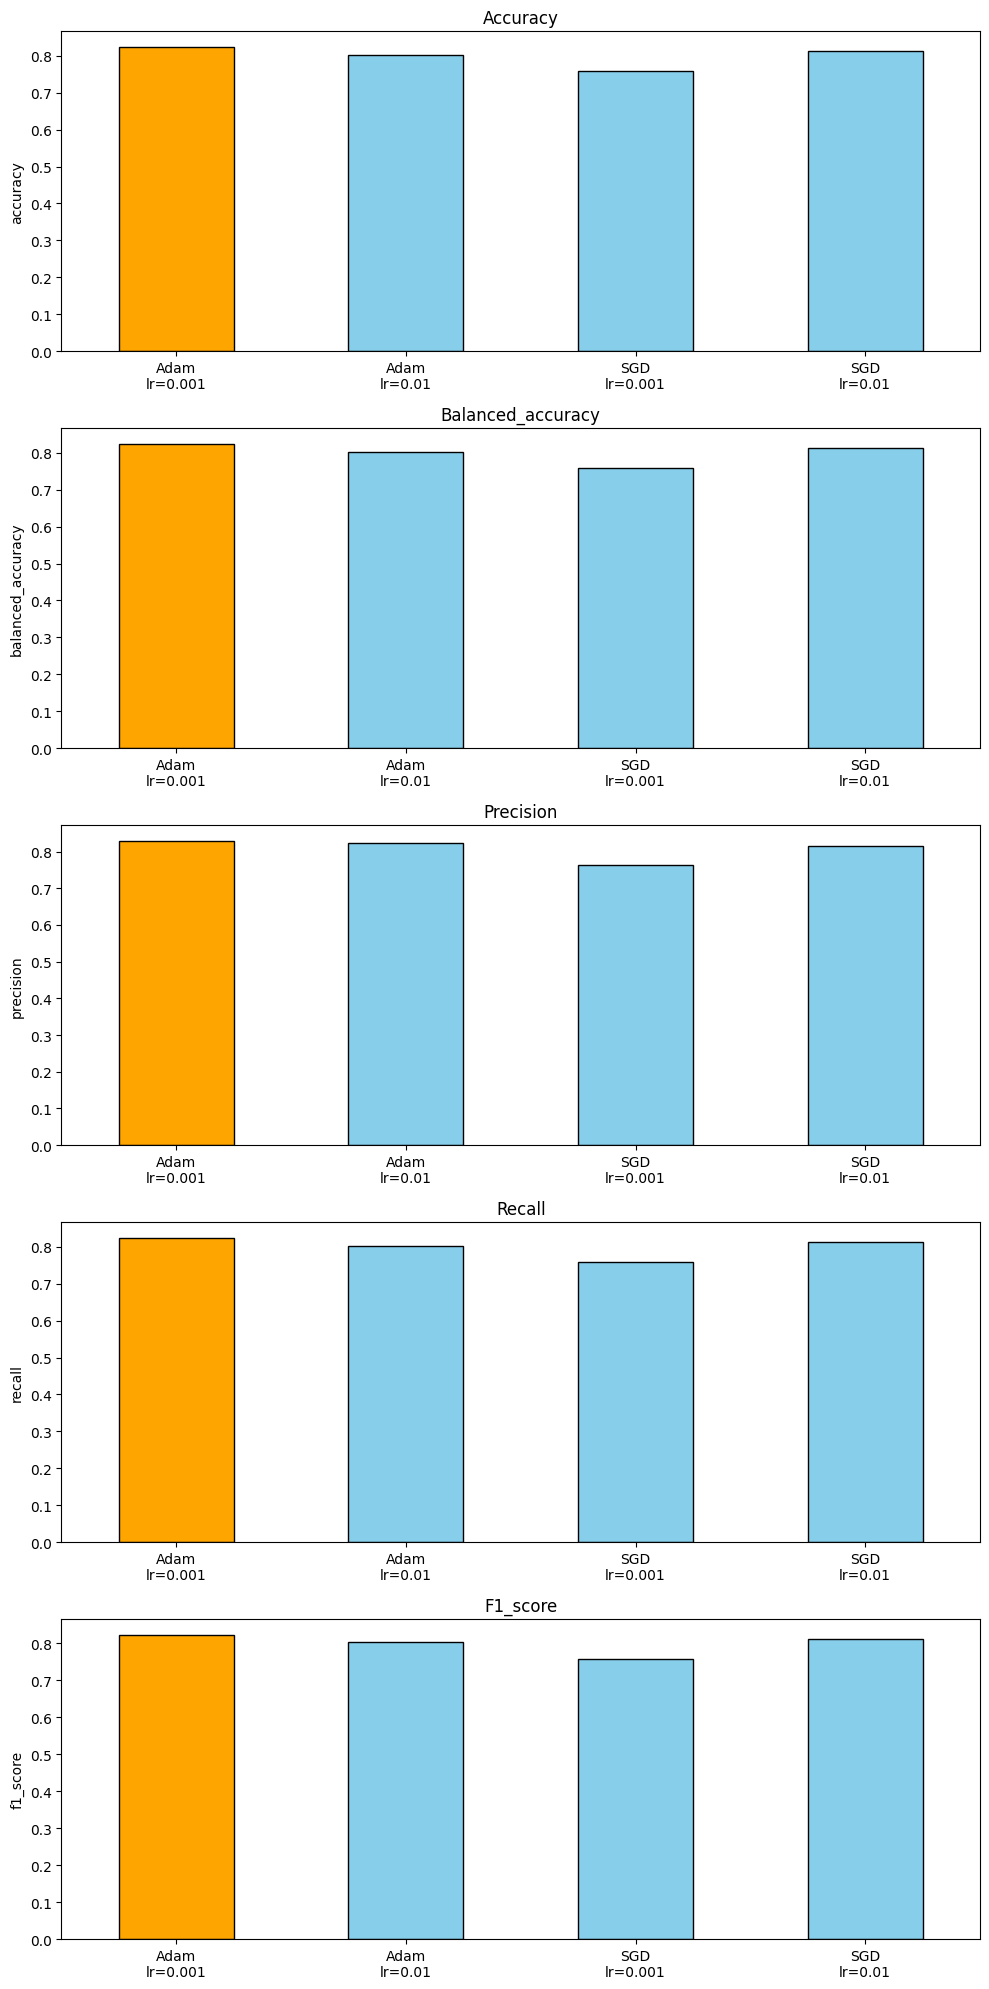

In [14]:
metrics = results.columns
fig, axes = plt.subplots(nrows=len(metrics), ncols=1, figsize=(10, 20))

for ax, metric in zip(axes, metrics):
    values = results[metric]
    colors = ['skyblue'] * len(values)

    if metric == 'avg_loss':
        best_idx = values.idxmin()
    else:
        best_idx = values.idxmax()

    best_pos = values.index.get_loc(best_idx)
    colors[best_pos] = 'orange'

    values.plot(
        kind='bar',
        ax=ax,
        title=metric.capitalize(),
        color=colors,
        edgecolor='black'
    )
    ax.set_ylabel(metric)
    ax.set_xlabel('')

    # Improve x-axis labels
    ax.set_xticklabels(
        [f'{o}\nlr={lr}' for o, lr in results.index],
        rotation=0,
        ha='center'
    )

plt.tight_layout()
plt.show()

### 3.4 Confusion Matrix

| CNN | MLP |
|---------|----------|
| 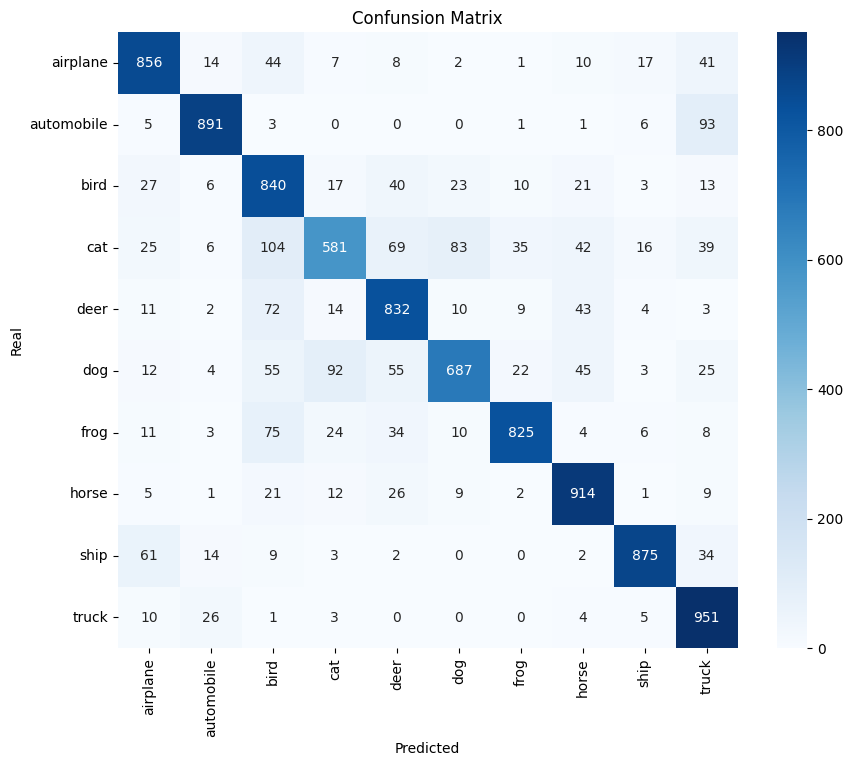 | 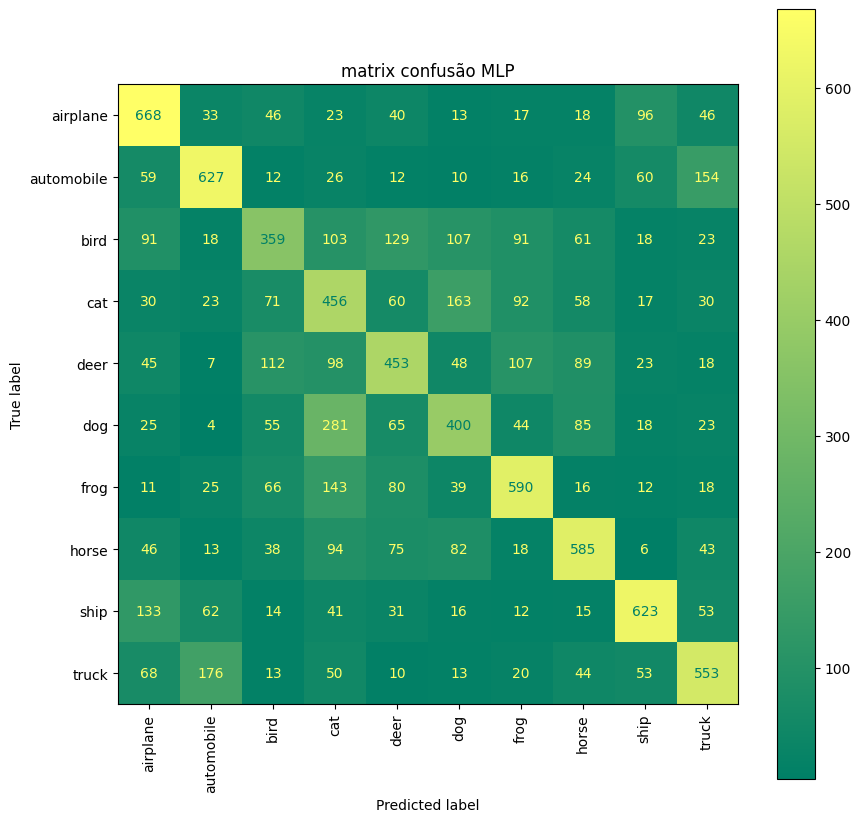 |


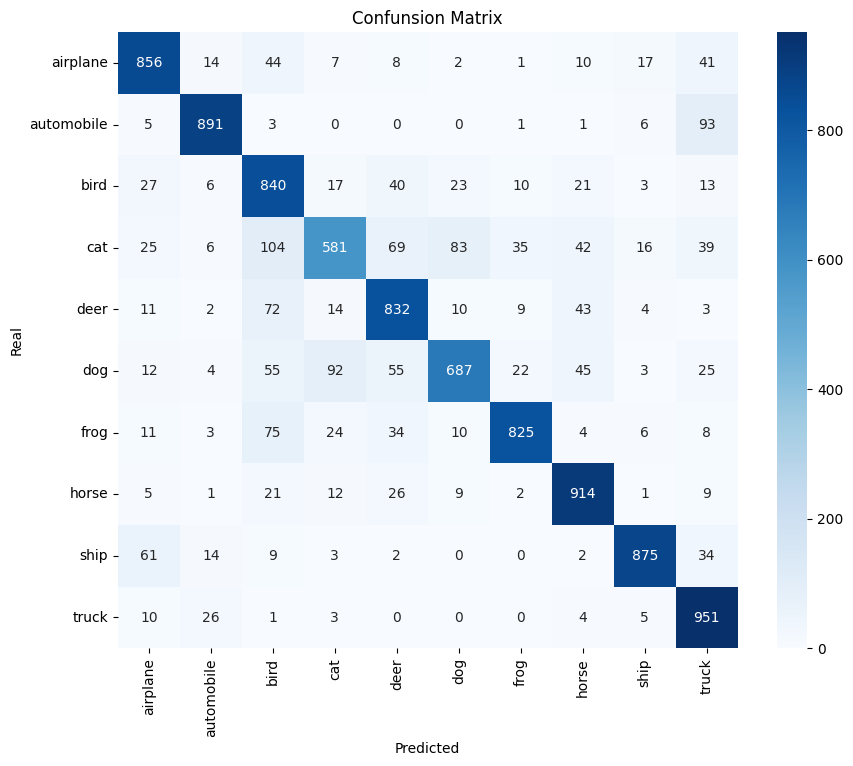

In [15]:
cm = confusion_matrix(labels, predictions)
classes = train_dataset.classes

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes,
            yticklabels=classes)
plt.xlabel('Predicted')
plt.ylabel('Real')
plt.title('Confunsion Matrix')
plt.show()

#### 3.5 Classifying Images

##### Definition of Methods

In [20]:
def plot_value_array(predictions_array, true_label):
    true_label = int(true_label)
    predictions_array = predictions_array.detach().cpu().numpy()
    predicted_label = np.argmax(predictions_array)

    plt.grid(False)
    plt.xticks(range(len(predictions_array)))
    plt.yticks([])
    bars = plt.bar(range(len(predictions_array)), predictions_array, color="#777777")
    plt.ylim([0, 1])

    bars[predicted_label].set_color('red')
    bars[true_label].set_color('blue')

def plot_tests():
    best_cnn.eval()
    num_rows = 4
    num_cols = 4
    num_images = num_rows * num_cols

    fig = plt.figure(figsize=(2 * 2 * num_cols, 2 * num_rows))
    classes = train_dataset.classes

    with torch.no_grad():
        for i, (image, label) in enumerate(test_loader):
            if i >= num_images:
                break

            image = image.to(device)

            output = best_cnn(image)
            probabilities = F.softmax(output, dim=1)[0]

            pred_label = output.argmax(dim=1)[0].item()

            image_vis = image[0].cpu() * 0.5 + 0.5
            image_vis = image_vis.permute(1, 2, 0)

            # Plot of the classified image
            plt.subplot(num_rows, 2 * num_cols, 2 * i + 1)
            plt.grid(False)
            plt.xticks([])
            plt.yticks([])

            true_label = label[0].item()

            title = f'Pred: {classes[pred_label]}\nTrue: {classes[true_label]}'
            plt.title(title, fontsize=10)
            plt.imshow(image_vis)

            # Probability plot
            plt.subplot(num_rows, 2 * num_cols, 2 * i + 2)
            plot_value_array(probabilities, true_label)

    plt.tight_layout()
    plt.show()

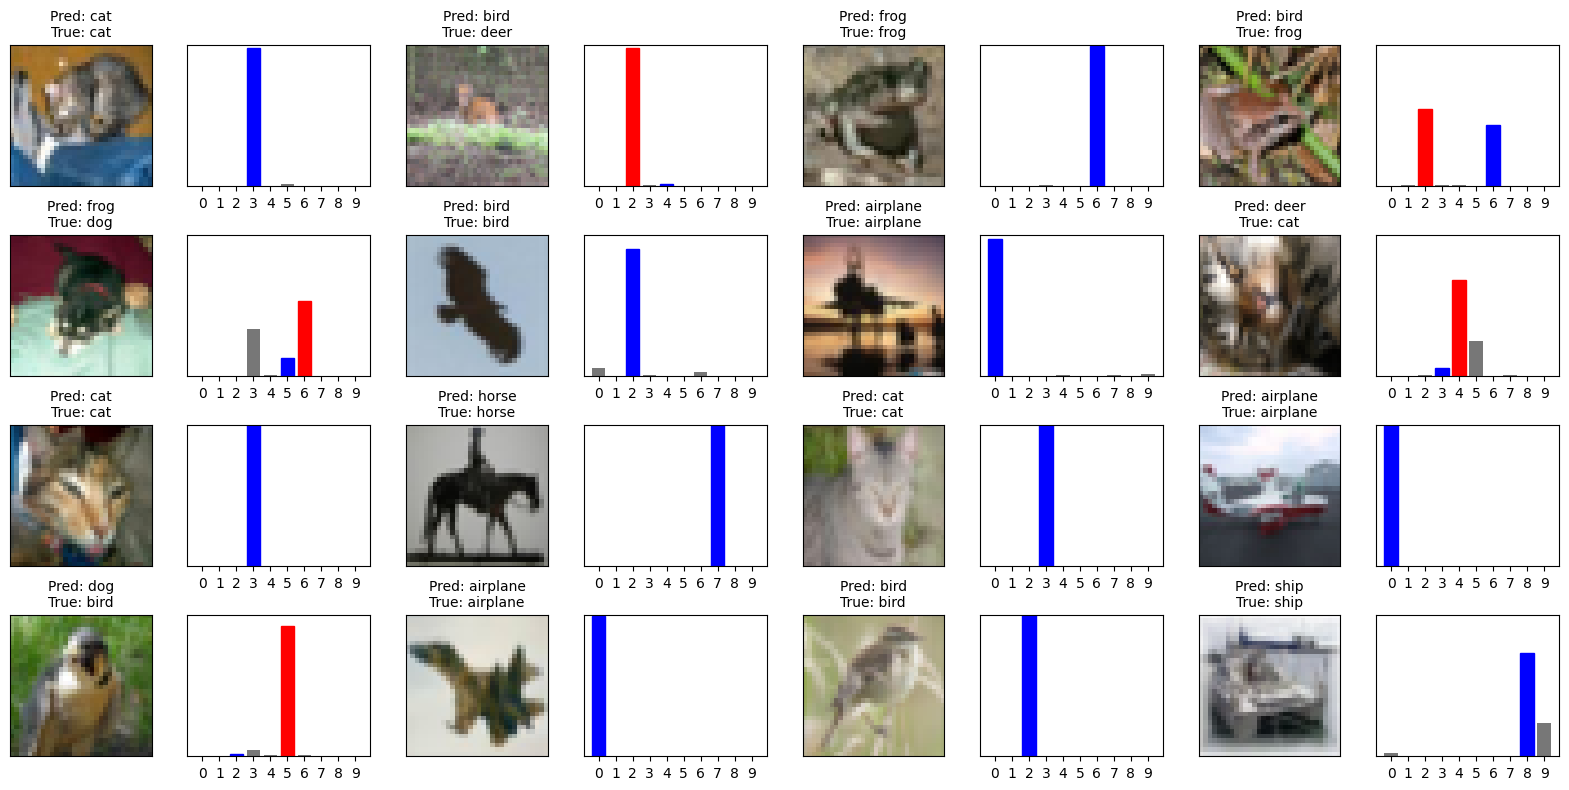

In [21]:
plot_tests()